In [1]:
from pynq import Overlay, allocate
import numpy as np
from PIL import Image
import time
import matplotlib.pyplot as plt

ol = Overlay('/home/xilinx/jupyter_notebooks/pynq_sobel/system_wrapper2.bit')
dma = ol.axi_dma_0
sobel_ip = ol.sobel_filter_0
print("Overlay loaded:", ol)

Overlay loaded: <pynq.overlay.Overlay object at 0xb38dba48>


In [2]:
resolutions = [(120, 160), (240, 320), (480, 640)]  # (rows, cols)
REPEAT = 20
THRESHOLD = 30

results = []

for (rows, cols) in resolutions:
    img = Image.open('/home/xilinx/jupyter_notebooks/pynq_sobel/img1.png') \
               .convert('L').resize((cols, rows))
    src_np = np.array(img, dtype=np.uint8)

    in_buf  = allocate(shape=(rows, cols), dtype=np.uint8)
    out_buf = allocate(shape=(rows, cols), dtype=np.uint8)
    in_buf[:] = src_np

    sobel_ip.write(0x10, rows)
    sobel_ip.write(0x18, cols)
    sobel_ip.write(0x20, THRESHOLD)

    times = []
    for _ in range(REPEAT):
        out_buf[:] = 0
        t0 = time.time()
        sobel_ip.write(0x00, 0x01)
        dma.recvchannel.transfer(out_buf)
        dma.sendchannel.transfer(in_buf)
        dma.sendchannel.wait()
        dma.recvchannel.wait()
        times.append((time.time() - t0) * 1000)

    avg_ms  = np.mean(times)
    fps     = 1000 / avg_ms
    pixels  = rows * cols
    nonzero = np.count_nonzero(out_buf)

    results.append({
        'resolution': f'{cols}x{rows}',
        'pixels': pixels,
        'avg_ms': round(avg_ms, 2),
        'fps': round(fps, 1),
        'nonzero': nonzero
    })

    in_buf.freebuffer()
    out_buf.freebuffer()
    print(f"{cols}x{rows}: {avg_ms:.2f} ms  {fps:.1f} FPS  edge pixels={nonzero}")

160x120: 0.95 ms  1049.8 FPS  edge pixels=10611
320x240: 1.57 ms  637.7 FPS  edge pixels=36366
640x480: 4.03 ms  247.8 FPS  edge pixels=125270


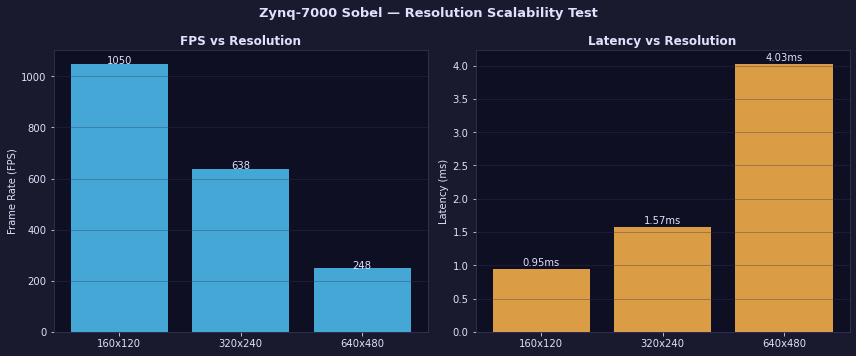

Saved to resolution_benchmark.png


In [3]:
labels  = [r['resolution'] for r in results]
fps_list = [r['fps'] for r in results]
ms_list  = [r['avg_ms'] for r in results]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor('#1a1a2e')
BG = '#0f0f23'; TC = '#e0e0ff'; BLUE = '#4fc3f7'; AMBER = '#ffb74d'

for ax in (ax1, ax2):
    ax.set_facecolor(BG)
    ax.tick_params(colors=TC)
    for sp in ax.spines.values(): sp.set_edgecolor('#333355')
    ax.yaxis.label.set_color(TC)
    ax.xaxis.label.set_color(TC)
    ax.grid(axis='y', color='#333355', linewidth=0.5, alpha=0.7)

bars1 = ax1.bar(labels, fps_list, color=BLUE, alpha=0.85)
for b, v in zip(bars1, fps_list):
    ax1.text(b.get_x()+b.get_width()/2, v+1, f'{v:.0f}', ha='center', color=TC, fontsize=10)
ax1.set_ylabel('Frame Rate (FPS)')
ax1.set_title('FPS vs Resolution', color=TC, fontweight='bold')

bars2 = ax2.bar(labels, ms_list, color=AMBER, alpha=0.85)
for b, v in zip(bars2, ms_list):
    ax2.text(b.get_x()+b.get_width()/2, v+0.05, f'{v:.2f}ms', ha='center', color=TC, fontsize=10)
ax2.set_ylabel('Latency (ms)')
ax2.set_title('Latency vs Resolution', color=TC, fontweight='bold')

fig.suptitle('Zynq-7000 Sobel — Resolution Scalability Test', color=TC, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/home/xilinx/jupyter_notebooks/pynq_sobel/resolution_benchmark.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
print("Saved to resolution_benchmark.png")

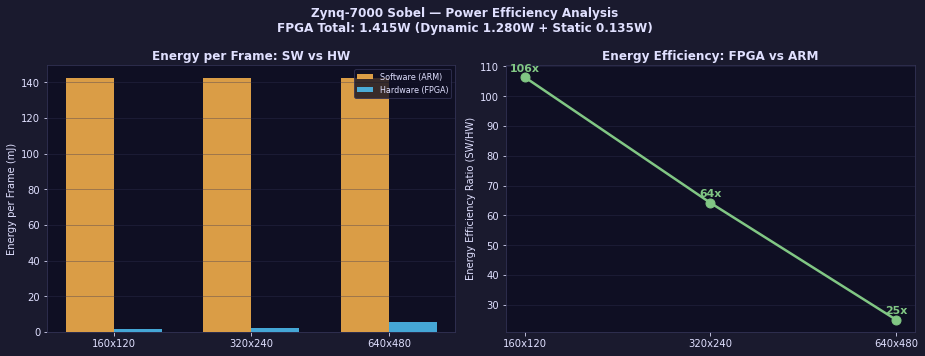

Saved to power_efficiency.png


In [4]:
import matplotlib.pyplot as plt
import numpy as np

resolutions = ['160x120', '320x240', '640x480']
hw_energy   = [1.34, 2.22, 5.70]   # mJ/frame
sw_energy   = [142.5, 142.5, 142.5]
efficiency  = [sw/hw for sw, hw in zip(sw_energy, hw_energy)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
fig.patch.set_facecolor('#1a1a2e')
BG = '#0f0f23'; TC = '#e0e0ff'; BLUE = '#4fc3f7'; AMBER = '#ffb74d'; GREEN = '#81c784'

for ax in (ax1, ax2):
    ax.set_facecolor(BG)
    ax.tick_params(colors=TC)
    for sp in ax.spines.values(): sp.set_edgecolor('#333355')
    ax.yaxis.label.set_color(TC)
    ax.xaxis.label.set_color(TC)
    ax.grid(axis='y', color='#333355', linewidth=0.5, alpha=0.7)

# 左图：每帧能耗对比
x = np.arange(len(resolutions)); w = 0.35
ax1.bar(x - w/2, sw_energy, w, label='Software (ARM)', color=AMBER, alpha=0.85)
ax1.bar(x + w/2, hw_energy, w, label='Hardware (FPGA)', color=BLUE,  alpha=0.85)
ax1.set_xticks(x); ax1.set_xticklabels(resolutions)
ax1.set_ylabel('Energy per Frame (mJ)')
ax1.set_title('Energy per Frame: SW vs HW', color=TC, fontweight='bold')
ax1.legend(fontsize=8, labelcolor=TC, facecolor=BG, edgecolor='#333355')

# 右图：能效比折线
ax2.plot(resolutions, efficiency, 'o-', color=GREEN, linewidth=2.5, markersize=9)
for i, v in enumerate(efficiency):
    ax2.text(i, v+2, f'{v:.0f}x', ha='center', color=GREEN, fontsize=11, fontweight='bold')
ax2.set_ylabel('Energy Efficiency Ratio (SW/HW)')
ax2.set_title('Energy Efficiency: FPGA vs ARM', color=TC, fontweight='bold')

fig.suptitle('Zynq-7000 Sobel — Power Efficiency Analysis\n'
             'FPGA Total: 1.415W (Dynamic 1.280W + Static 0.135W)',
             color=TC, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('/home/xilinx/jupyter_notebooks/pynq_sobel/power_efficiency.png',
            dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
print("Saved to power_efficiency.png")